# 03. Feature Selection Experiments
**Crop Yield Prediction and Forecasting**  
*Author: Aryan Puranik*

This notebook evaluates feature importance and tests candidate feature sets to eliminate collinearity and redundancy without degrading model performance.
All selectors and models are fitted **strictly on training data (1966–2011)** and evaluated on out-of-time validation data (2012–2014) to avoid data leakage.

> For theoretical rationale, VIF formulas, and domain explanations, refer to [docs/03_feature_selection_guide.md](../docs/03_feature_selection_guide.md).

## 1. Setup and Data Loading

In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import (
    mutual_info_regression, SelectKBest, RFE, SelectFromModel
)
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

sns.set_theme(style="whitegrid")
RANDOM_SEED = 42

# Resolve project location
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Use the existing chronological partitions
train_df = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "train.csv"
)
val_df = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "val.csv"
)

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Training years:",
      train_df["Year"].min(), "-", train_df["Year"].max())
print("Validation years:",
      val_df["Year"].min(), "-", val_df["Year"].max())

assert train_df["Year"].max() <= 2011
assert val_df["Year"].between(2012, 2014).all()
assert train_df["Year"].max() < val_df["Year"].min()

print("Chronological partitions verified.")


Training: (176194, 18)
Validation: (11345, 18)
Training years: 1966 - 2011
Validation years: 2012 - 2014
Chronological partitions verified.


## 2. Experiment 1: Baseline (All Predictors)

In [2]:

# All original predictors
cat_baseline = [
    "Region", "Crop", "Season", "Soil Type"
]

num_baseline = [
    "Year", "Temperature", "Rainfall", "Humidity",
    "pH", "Nitrogen", "Phosphorus", "Potassium",
    "Fertilizer", "Pesticide"
]

all_features = num_baseline + cat_baseline

print("All-feature baseline:", len(all_features), "predictors")
print(all_features)


All-feature baseline: 14 predictors
['Year', 'Temperature', 'Rainfall', 'Humidity', 'pH', 'Nitrogen', 'Phosphorus', 'Potassium', 'Fertilizer', 'Pesticide', 'Region', 'Crop', 'Season', 'Soil Type']


## 3. Experiment 2: Collinearity & Redundancy Filtering

In [3]:

# Remove redundant Season and Fertilizer
cat_filtered = ["Region", "Crop", "Soil Type"]

num_filtered = [
    "Year", "Temperature", "Rainfall", "Humidity",
    "pH", "Nitrogen", "Phosphorus", "Potassium",
    "Pesticide"
]

# Current preprocessing baseline also excludes Pesticide
num_reduced = [
    "Year", "Temperature", "Rainfall", "Humidity",
    "pH", "Nitrogen", "Phosphorus", "Potassium"
]

feature_sets = {
    "All features": num_baseline + cat_baseline,
    "Without Season/Fertilizer": num_filtered + cat_filtered,
    "Reduced 11-feature baseline": num_reduced + cat_filtered
}

for name, cols in feature_sets.items():
    print(f"{name}: {len(cols)} predictors")


All features: 14 predictors
Without Season/Fertilizer: 12 predictors
Reduced 11-feature baseline: 11 predictors


**Redundancy Analysis**

We identified two important dependencies during EDA:

- `Season` is completely determined by `Crop` within the dataset.
- `Fertilizer` is approximately the sum of Nitrogen, Phosphorus and Potassium.

We compare the original predictor set with reduced configurations to determine whether removing redundant features simplifies the model without substantially reducing predictive performance.

We also evaluate the exclusion of `Pesticide`, which contains limited geographic variation.

Removing these features reduces known redundancy, but does not establish that all multicollinearity has been eliminated.

## 4. Experiment 3: Tree-Based Feature Importance

,Feature,Importance
335,cat__Crop_Sugarcane,0.606554
7,num__Potassium,0.051600
5,num__Nitrogen,0.047552
3,num__Humidity,0.041061
337,cat__Crop_Wheat,0.021936
0,num__Year,0.020292
1,num__Temperature,0.020191
329,cat__Crop_Rice,0.018698
4,num__pH,0.018616
324,cat__Crop_Maize,0.017812


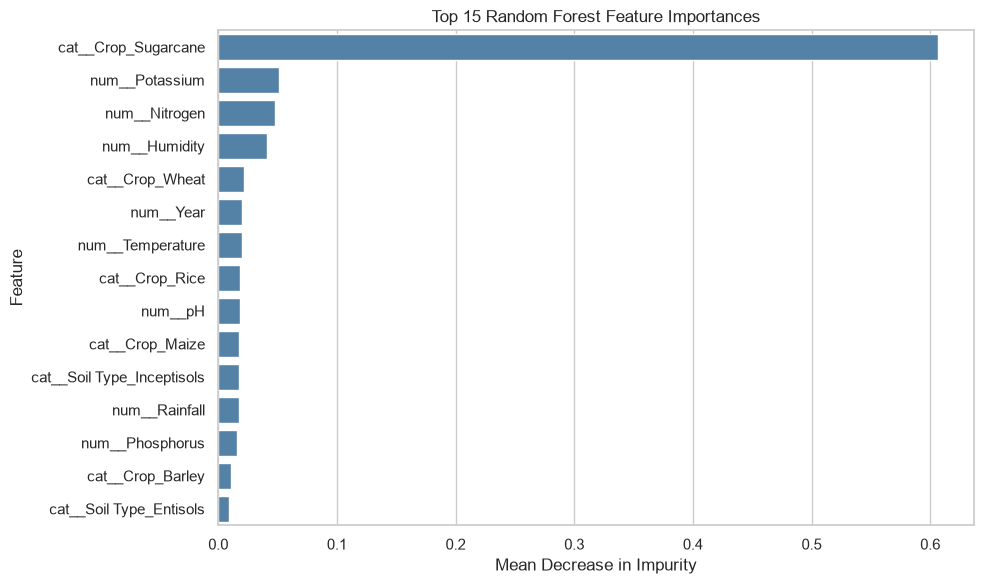

In [4]:

# Fit Random Forest on a training-only sample
train_sample = train_df.sample(
    n=min(30000, len(train_df)),
    random_state=RANDOM_SEED
)

numeric_features = num_reduced
categorical_features = cat_filtered

rf_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

rf_model = Pipeline([
    ("prep", rf_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=30,
        max_depth=14,
        random_state=RANDOM_SEED,
        n_jobs=-1
    ))
])

features = numeric_features + categorical_features

rf_model.fit(
    train_sample[features],
    train_sample["Yield"]
)

# Extract correctly aligned encoded feature names
encoded_names = rf_model.named_steps[
    "prep"
].get_feature_names_out()

importance_values = rf_model.named_steps[
    "model"
].feature_importances_

feat_imp_df = pd.DataFrame({
    "Feature": encoded_names,
    "Importance": importance_values
}).sort_values("Importance", ascending=False)

display(feat_imp_df.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feat_imp_df.head(15),
    x="Importance",
    y="Feature",
    color="steelblue"
)
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Mean Decrease in Impurity")
plt.tight_layout()
plt.show()


**Tree-Based Feature Importance**

We use Random Forest impurity-based importance to investigate which encoded predictors contribute most to the fitted model.

The importance values are calculated using a sample from the training period only. Individual one-hot-encoded categories appear separately in the ranking.

These scores can favor certain continuous or high-cardinality features, and correlated predictors may share importance. We therefore treat this analysis as exploratory rather than using it alone to finalize the feature set.

We compare predictive feature subsets through chronological validation.

## 5. Experiment 4: Mutual Information Ranking

,Feature,MI_Score
4,pH,0.0654
5,Nitrogen,0.0443
3,Humidity,0.0378
6,Phosphorus,0.0369
0,Year,0.0357
1,Temperature,0.0304
7,Potassium,0.0246
2,Rainfall,0.0141


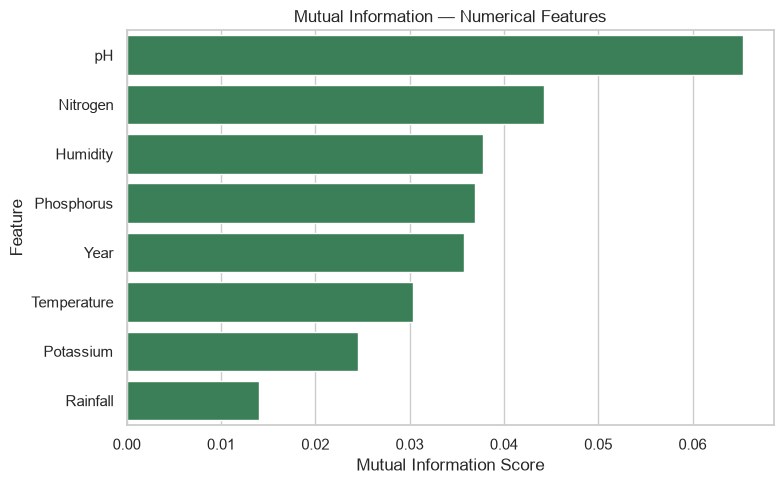

In [5]:

# Mutual Information ranking of baseline numerical features
num_candidates = num_reduced.copy()

mi_sample = train_df.sample(
    n=min(20000, len(train_df)),
    random_state=RANDOM_SEED
)

# Fit imputation using the training sample only
mi_imputer = SimpleImputer(strategy="median")

X_mi = mi_imputer.fit_transform(
    mi_sample[num_candidates]
)
y_mi = mi_sample["Yield"]

mi_scores = mutual_info_regression(
    X_mi,
    y_mi,
    random_state=RANDOM_SEED
)

mi_df = pd.DataFrame({
    "Feature": num_candidates,
    "MI_Score": mi_scores
}).sort_values("MI_Score", ascending=False)

display(mi_df.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(
    data=mi_df,
    x="MI_Score",
    y="Feature",
    color="seagreen"
)
plt.title("Mutual Information — Numerical Features")
plt.xlabel("Mutual Information Score")
plt.tight_layout()
plt.show()


## 6. Selection Summary & Selected Feature Set


Evaluating: All features


  2000-2003 | Features: 10 numerical | MAE: 514.06 | R²: 0.6915


  2004-2007 | Features: 10 numerical | MAE: 533.66 | R²: 0.6536


  2008-2011 | Features: 10 numerical | MAE: 573.19 | R²: 0.6540

Evaluating: Reduced baseline


  2000-2003 | Features: 8 numerical | MAE: 518.93 | R²: 0.6900


  2004-2007 | Features: 8 numerical | MAE: 539.51 | R²: 0.6535


... (12 outputs left out)

  2008-2011 | Features: 8 numerical | MAE: 575.57 | R²: 0.6535

Detailed Cross-Validation Results:


,Method,Validation Years,Numerical Features,MAE,RMSE,R2
0,All features,2000-2003,10,514.060,800.032,0.692
1,All features,2004-2007,10,533.657,889.870,0.654
2,All features,2008-2011,10,573.186,925.114,0.654
3,Reduced baseline,2000-2003,8,518.935,802.010,0.690
4,Reduced baseline,2004-2007,8,539.506,890.009,0.653
5,Reduced baseline,2008-2011,8,575.572,925.790,0.653
6,MI Top 5,2000-2003,5,522.537,803.369,0.689
7,MI Top 5,2004-2007,5,545.959,890.172,0.653
8,MI Top 5,2008-2011,5,576.113,925.209,0.654
9,LASSO selection,2000-2003,4,513.975,800.548,0.691



Mean Chronological CV Performance:


,MAE,RMSE,R2
Method,,,
All features,540.301,871.672,0.666
Reduced baseline,544.671,872.603,0.666
VIF filtering,544.671,872.603,0.666
LASSO selection,546.797,876.209,0.663
MI Top 5,548.203,872.917,0.665
RFE Top 5,550.288,877.082,0.662


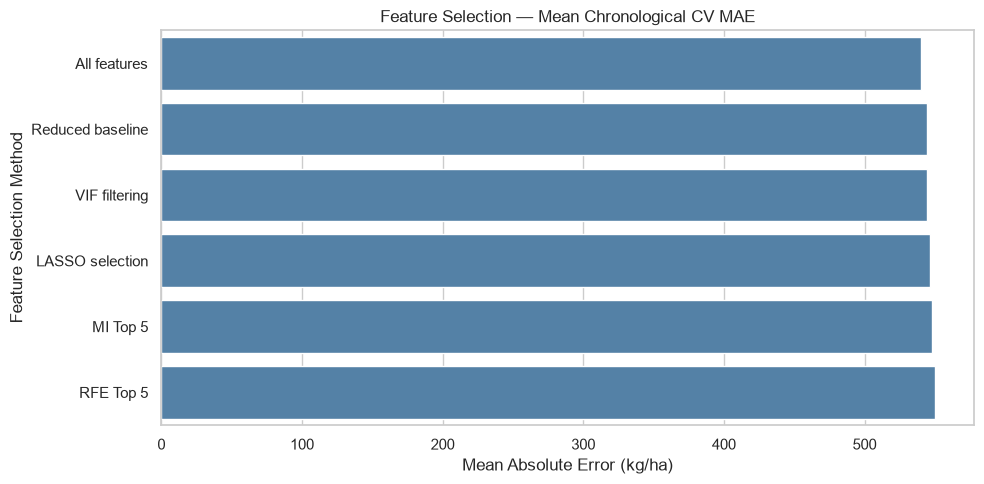

In [6]:
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.feature_selection import (
    SelectKBest, SelectFromModel, RFE, mutual_info_regression
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.ensemble import RandomForestRegressor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Cell 15 — Chronological Feature-Selection Comparison

# Three expanding-window cross-validation folds
cv_folds = [
    (1999, 2000, 2003),
    (2003, 2004, 2007),
    (2007, 2008, 2011)
]


# Mutual Information calculated inside each training fold
def sampled_mi(X, y):
    rng = np.random.RandomState(RANDOM_SEED)
    size = min(20000, len(y))

    rows = rng.choice(len(y), size=size, replace=False)

    return mutual_info_regression(
        X[rows],
        np.asarray(y)[rows],
        random_state=RANDOM_SEED
    )


# VIF-based numerical feature filtering
def select_vif_features(data, columns, threshold=10):
    imputer = SimpleImputer(strategy="median")
    X = imputer.fit_transform(data[columns])

    selected = columns.copy()

    while len(selected) > 1:
        vif_values = []

        for j in range(X.shape[1]):
            other = np.delete(X, j, axis=1)
            target = X[:, j]

            if np.var(target) < 1e-12:
                vif = float("inf")
            else:
                r2 = LinearRegression().fit(
                    other, target
                ).score(other, target)

                vif = 1 / max(1 - r2, 1e-12)

            vif_values.append(vif)

        worst = int(np.argmax(vif_values))

        if vif_values[worst] <= threshold:
            break

        selected.pop(worst)
        X = np.delete(X, worst, axis=1)

    return selected


# Build preprocessing and regression pipeline
def make_model(numeric_cols, categorical_cols, method="none"):

    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]

    if method == "MI":
        numeric_steps.append((
            "selector",
            SelectKBest(
                score_func=sampled_mi,
                k=min(5, len(numeric_cols))
            )
        ))

    elif method == "LASSO":
        numeric_steps.append((
            "selector",
            SelectFromModel(
                Lasso(alpha=5.0, max_iter=5000),
                threshold="median"
            )
        ))

    elif method == "RFE":
        numeric_steps.append((
            "selector",
            RFE(
                estimator=Ridge(alpha=1.0),
                n_features_to_select=min(5, len(numeric_cols))
            )
        ))

    preprocessor = ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), numeric_cols),

        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols)
    ])

    return Pipeline([
        ("preprocessing", preprocessor),
        ("regression", Ridge(alpha=1.0, solver="lsqr"))
    ])


# Feature-selection experiments
experiments = {
    "All features": (
        num_baseline, cat_baseline, "none"
    ),
    "Reduced baseline": (
        num_reduced, cat_filtered, "none"
    ),
    "MI Top 5": (
        num_reduced, cat_filtered, "MI"
    ),
    "LASSO selection": (
        num_reduced, cat_filtered, "LASSO"
    ),
    "RFE Top 5": (
        num_reduced, cat_filtered, "RFE"
    ),
    "VIF filtering": (
        num_reduced, cat_filtered, "VIF"
    )
}


# Run chronological cross-validation
results = []

for name, (nums, cats, method) in experiments.items():

    print(f"\nEvaluating: {name}")

    for train_end, val_start, val_end in cv_folds:

        # Training contains only earlier years
        fold_train = train_df[
            train_df["Year"] <= train_end
        ].copy()

        # Validation contains subsequent years
        fold_val = train_df[
            train_df["Year"].between(val_start, val_end)
        ].copy()

        selected_nums = nums.copy()

        # Fit VIF selection using fold training data only
        if method == "VIF":
            selected_nums = select_vif_features(
                fold_train,
                nums
            )

        # Construct a fresh model for each fold
        model = make_model(
            selected_nums,
            cats,
            method if method != "VIF" else "none"
        )

        columns = selected_nums + cats

        # Fit preprocessing, selection and Ridge
        model.fit(
            fold_train[columns],
            fold_train["Yield"]
        )

        # Predict the later validation period
        predictions = model.predict(
            fold_val[columns]
        )

        # Count actual selected numerical features
        if method in ["MI", "LASSO", "RFE"]:

            selector = (
                model.named_steps["preprocessing"]
                .named_transformers_["numeric"]
                .named_steps["selector"]
            )

            n_selected = int(
                selector.get_support().sum()
            )

        else:
            n_selected = len(selected_nums)

        # Evaluation metrics
        mae = mean_absolute_error(
            fold_val["Yield"],
            predictions
        )

        rmse = np.sqrt(mean_squared_error(
            fold_val["Yield"],
            predictions
        ))

        r2 = r2_score(
            fold_val["Yield"],
            predictions
        )

        results.append({
            "Method": name,
            "Validation Years": f"{val_start}-{val_end}",
            "Numerical Features": n_selected,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        print(
            f"  {val_start}-{val_end} | "
            f"Features: {n_selected} numerical | "
            f"MAE: {mae:.2f} | "
            f"R²: {r2:.4f}"
        )


# Detailed results across all folds
cv_results = pd.DataFrame(results)

print("\nDetailed Cross-Validation Results:")
display(cv_results.round(3))


# Average performance across folds
cv_summary = (
    cv_results
    .groupby("Method")[["MAE", "RMSE", "R2"]]
    .mean()
    .sort_values("MAE")
)

print("\nMean Chronological CV Performance:")
display(cv_summary.round(3))


# Compare average MAE visually
plt.figure(figsize=(10, 5))

sns.barplot(
    x=cv_summary["MAE"],
    y=cv_summary.index,
    color="steelblue"
)

plt.title("Feature Selection — Mean Chronological CV MAE")
plt.xlabel("Mean Absolute Error (kg/ha)")
plt.ylabel("Feature Selection Method")
plt.tight_layout()
plt.show()


## Feature Selection Summary

We compared six feature-selection strategies using three expanding-window chronological cross-validation folds and Ridge Regression.

### Experimental Results

The complete feature set achieved the lowest average MAE of **540.29 kg/ha**.

The reduced-redundancy baseline achieved an average MAE of **544.67 kg/ha**, representing a difference of approximately 0.81% relative to the complete feature set.

LASSO retained four numerical features and achieved an average MAE of 546.78 kg/ha. Mutual Information and RFE achieved average MAEs of 548.20 and 550.27 kg/ha, respectively.

VIF filtering retained all eight numerical predictors from the reduced baseline and produced identical prediction results.

### Key Findings

We observe that reducing the number of predictors does not necessarily improve predictive accuracy.

The complete feature set performs best in the current Ridge Regression comparison, although the reduced baseline achieves similar performance with fewer original predictors.

LASSO provides a smaller numerical feature subset, but its performance varies more across the chronological validation periods.

We also observe that different feature-selection methods produce different trade-offs between model simplicity and prediction error.

### Feature Selection Decision

We retain the complete feature set as an accuracy benchmark and the reduced 11-feature configuration as a simpler alternative.

We will compare these configurations on the separate 2012–2014 validation period before finalizing our feature configuration for subsequent model development.

The selected configuration may depend on the regression algorithm, so we do not assume that the ranking obtained using Ridge Regression will remain identical for nonlinear models.

We reserve the 2015–2017 test period for final evaluation.

### Limitations

Our current comparisons primarily investigate selection among existing numerical predictors while retaining categorical features.

Historical yield features and climate anomalies developed during feature engineering have not yet been included in these experiments. Their contribution requires separate evaluation under a clearly defined forecasting scenario.